# Demonstration Notebook
This notebook demonstrates and compares three ABSA implementations:
1. Lexicon-Based ABSA (spaCy + Sentiment Lexicon)
2. Transformer-Based ABSA (Pretrained Transformer Model)
3. LLM-Based ABSA using Ollama (Local LLM)

**The goal is to:**
- Run all three models on sample review data
- Compare their outputs on identical inputs
- Measure accuracy and runtime
- Analyze strengths, weaknesses, and trade-offs


In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.lexicon_absa import LexiconABSA
from src.transformer_absa import TransformerABSA
from src.llm_absa import LLMABSA

## 1. Load and Preview Data

In [2]:
# We'll use a subset of Yelp reviews as the evaluation dataset.
# Each review includes 'text' and 'stars' fields (1–5 rating scale).

df = pd.read_json("../data/yelp_sample_20k.json", lines=True)
df.head()

,text,stars
0,Fresh spring water... check!\nHugely portioned...,5
1,"I tried their decaf latte which was tasty, foa...",4
2,Amazing Bagels!! My favorite place ever! Super...,5
3,"Well, I visited UAL for the first time today b...",5
4,Eight of us came here for brunch for my birthd...,4


## 2. Sample a Subset for Evaluation

In [3]:
# To keep runtime manageable, we'll sample 20 reviews randomly.
# This allows a fair comparison while still showing representative examples.

sample_df = df.sample(20, random_state=42).reset_index(drop=True)
sample_df.head()

,text,stars
0,I used to get take-out from here once a week b...,5
1,Consistent service and quality of food. My dau...,5
2,We were visiting and came out to Play two nigh...,4
3,We got the breakfast sandwiches and potato sid...,5
4,Food court has only 2 options and 1 line feeds...,1


## 3. Initialize All Three ABSA Implementations

In [4]:
# Initialize each ABSA model.
# Make sure spaCy model and Ollama LLM are properly installed before running.

lex_model = LexiconABSA()
trf_model = TransformerABSA()
llm_model = LLMABSA("llama3")  # Ensure Ollama is running locally

Device set to use cpu
C:\Users\lesle\PycharmProjects\SentimentProject\.venv\Lib\site-packages\transformers\convert_slow_tokenizer.py:564: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


LLMABSA initialized with model: llama3


## 4. Run ABSA Across All Models

In [5]:
# We'll process each review with all three models.
# For each model, we'll store:
#   • Extracted (aspect, sentiment) pairs
#   • Processing time

results = []

for i, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    text = row["text"]
    row_result = {"review": text}

    for model_name, model in [
        ("LexiconABSA", lex_model),
        ("TransformerABSA", trf_model),
        ("LLMABSA", llm_model),
    ]:
        start = time.time()
        aspects = model.analyze(text)
        end = time.time()

        row_result[f"{model_name}_time"] = round(end - start, 3)
        row_result[f"{model_name}_aspects"] = [(a.aspect, a.sentiment) for a in aspects]

    results.append(row_result)

comp_df = pd.DataFrame(results)
comp_df.head()

100%|██████████| 20/20 [13:28<00:00, 40.45s/it]


,review,LexiconABSA_time,LexiconABSA_aspects,TransformerABSA_time,TransformerABSA_aspects,LLMABSA_time,LLMABSA_aspects
0,I used to get take-out from here once a week b...,0.021,"[(buffet, positive), (friendly staff, positive...",1.806,"[(buffet, positive), (staff, positive), (food,...",109.794,"[(restaurant, positive), (buffet, positive), (..."
1,Consistent service and quality of food. My dau...,0.172,"[(daughter, positive), (server, positive), (yu...",2.248,"[(service, positive), (food, neutral), (veggie...",36.800,"[(service, positive), (food, positive), (veggi..."
2,We were visiting and came out to Play two nigh...,0.095,"[(drag show, positive), (separate club floor, ...",2.748,"[(floor, positive), (patio, positive), (Staff,...",42.685,"[(drag show, positive), (club floor, positive)..."
3,We got the breakfast sandwiches and potato sid...,0.048,"[(best breakfast sandwiches, positive), (perfe...",2.350,"[(breakfast sandwiches, positive), (bread, pos...",18.139,"[(breakfast sandwiches, positive), (pastries, ..."
4,Food court has only 2 options and 1 line feeds...,0.060,[],1.975,"[(Wait, negative), (staff, negative)]",25.258,"[(food court, negative), (staff, negative), (o..."


## 5. Interactive Comparison Function

In [6]:
# Function to display model comparisons for a given review
def show_comparison(idx):
    row = comp_df.iloc[idx]
    print(f"Review {idx+1}: {row['review'][:1000]}...\n")
    for model_name in ["LexiconABSA", "TransformerABSA", "LLMABSA"]:
        print(f"--- {model_name} ---")
        aspects = row[f"{model_name}_aspects"]
        if not aspects:
            print("No aspects detected.")
        else:
            for asp, sent in aspects:
                print(f"   ➜ {asp:<25} | {sent}")
        print(f"Runtime: {row[f'{model_name}_time']}s\n")


In [7]:
# Example comparisons (adjust indices to get a desired review)
show_comparison(0)

Review 1: I used to get take-out from here once a week before I moved a few years ago! Now my husband and I are back in Drexel Hill and we frequent this restaurant quite a bit and I'm not complaining about that. Their buffet is always fresh and never disappoints! Friendly staff and I have to say again that their food is amazing. 

Side note: Great gluten free options and vegan options too! Also, they use cloth napkins which is great for cutting down waste (which I really appreciated)...

--- LexiconABSA ---
   ➜ buffet                    | positive
   ➜ friendly staff            | positive
   ➜ food                      | positive
Runtime: 0.021s

--- TransformerABSA ---
   ➜ buffet                    | positive
   ➜ staff                     | positive
   ➜ food                      | positive
   ➜ options                   | positive
   ➜ napkins                   | positive
Runtime: 1.806s

--- LLMABSA ---
   ➜ restaurant                | positive
   ➜ buffet                    | po

In [8]:
show_comparison(5)

Review 6: I wish I could justify a higher review for WKND Hang Suite because my friends and I plowed through some of the most amazing chicken tenders, fried pickles and loaded fries any of us had ever had, but the service left something to be desired. The bartender was really helpful, but our server once we moved to a seating area seemed overwhelmed by the number of orders for food our group of 10+ ordered. Chicken tenders came out within ten minutes and yet fries inexplicably took over half an hour to arrive. Also, every surface in the place was incredibly sticky, from the bartop to the tables in our seating area.

The vibe at this place was awesome, and I'd love to go back to try their hookah and have some more of those chicken tenders, but I'm not sure I'll be back....

--- LexiconABSA ---
   ➜ amazing chicken tenders   | positive
   ➜ bartender                 | positive
   ➜ vibe                      | positive
Runtime: 0.083s

--- TransformerABSA ---
   ➜ chicken tenders         

In [9]:
show_comparison(10)

Review 11: I ate here once got take away food was JUST OKAY! Nothing to brag about, cou ppl le guys from work wanted to go to a buffet I called and their price is $14pp which is a little high compared to other indian buffets in the area. I mean the food isnt that great, adjust the price and quality....

--- LexiconABSA ---
   ➜ food                      | positive
   ➜ food                      | positive
Runtime: 0.026s

--- TransformerABSA ---
   ➜ price                     | negative
Runtime: 1.126s

--- LLMABSA ---
   ➜ food                      | negative
   ➜ price                     | negative
Runtime: 19.75s



## 6. Compute Approximate Accuracy

In [10]:
# We'll estimate sentiment accuracy using Yelp stars as a proxy label.
# This is a coarse measure but useful for trend analysis.

def yelp_to_sentiment(stars):
    if stars >= 4:
        return "positive"
    elif stars == 3:
        return "neutral"
    else:
        return "negative"

sample_df["true_sentiment"] = sample_df["stars"].apply(yelp_to_sentiment)

def aggregate_sentiment(preds):
    if not preds:
        return "neutral"
    pos = sum(1 for _, s in preds if s == "positive")
    neg = sum(1 for _, s in preds if s == "negative")
    if pos > neg:
        return "positive"
    elif neg > pos:
        return "negative"
    return "neutral"


## 7. Compute Metrics: Accuracy, Runtime, and Aspects

In [11]:
# Compute overall accuracy and average runtime per model.
# Also compute average number of aspects detected per review

scores = []
for model_name in ["LexiconABSA", "TransformerABSA", "LLMABSA"]:
    pred_sentiments = [
        aggregate_sentiment(row[f"{model_name}_aspects"]) for _, row in comp_df.iterrows()
    ]
    acc = (pd.Series(pred_sentiments) == sample_df["true_sentiment"]).mean()
    avg_time = comp_df[f"{model_name}_time"].mean()
    avg_aspects = comp_df[f"{model_name}_aspects"].apply(len).mean()

    scores.append((model_name, round(acc, 3), round(avg_time, 3), round(avg_aspects, 2)))

metrics_df = pd.DataFrame(scores, columns=["Model", "Accuracy", "Avg_Runtime(s)", "Avg_Aspects"])

In [12]:
print("ABSA Model Performance Summary")
display(metrics_df.style.set_caption("Performance Metrics Across ABSA Implementations"))


ABSA Model Performance Summary


,Model,Accuracy,Avg_Runtime(s),Avg_Aspects
0,LexiconABSA,0.700000,0.058000,3.050000
1,TransformerABSA,0.800000,2.812000,4.300000
2,LLMABSA,0.800000,37.569000,3.700000


## 8.Visualize Metrics

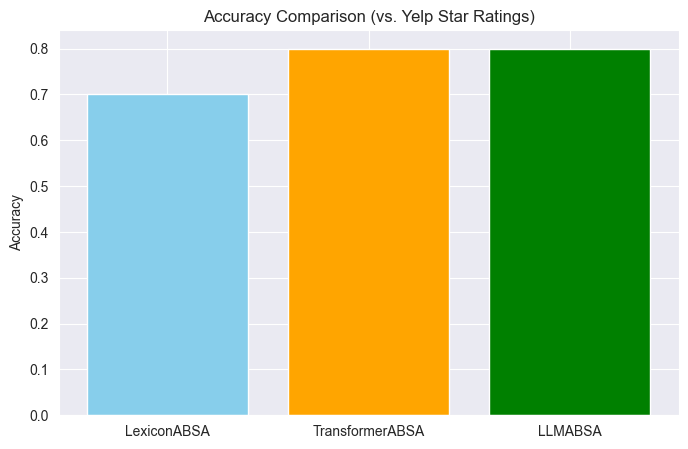

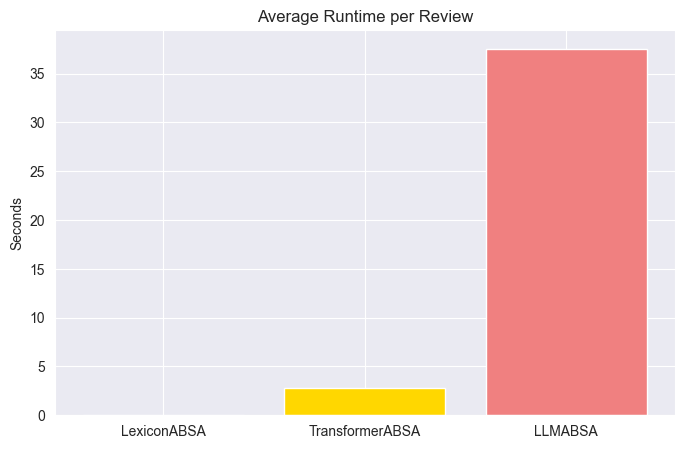

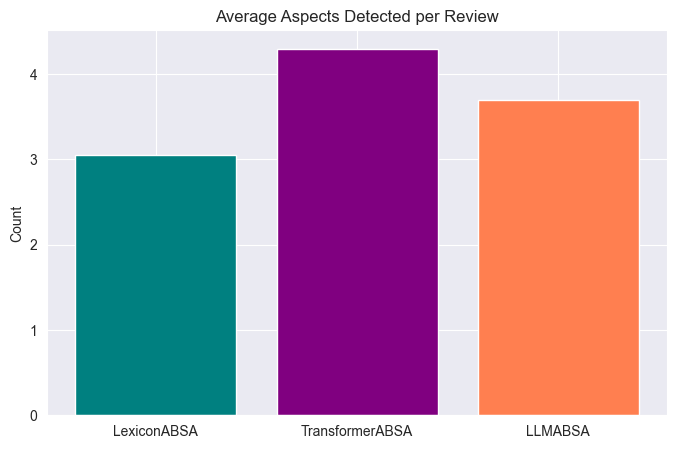

In [13]:
# Accuracy comparison
plt.figure(figsize=(8,5))
plt.bar(metrics_df["Model"], metrics_df["Accuracy"], color=["skyblue","orange","green"])
plt.title("Accuracy Comparison (vs. Yelp Star Ratings)")
plt.ylabel("Accuracy")
plt.show()

# Runtime comparison
plt.figure(figsize=(8,5))
plt.bar(metrics_df["Model"], metrics_df["Avg_Runtime(s)"], color=["gray","gold","lightcoral"])
plt.title("Average Runtime per Review")
plt.ylabel("Seconds")
plt.show()

# Average Aspects comparison
plt.figure(figsize=(8,5))
plt.bar(metrics_df["Model"], metrics_df["Avg_Aspects"], color=["teal","purple","coral"])
plt.title("Average Aspects Detected per Review")
plt.ylabel("Count")
plt.show()


## Results Showcase Side-by-Side Comparisons

In [16]:
# A few qualitative examples to illustrate how each model differs.

showcase_examples = [
    """Great spot for brunch! The avocado toast was fresh and flavorful. Only complaint is that it gets pretty noisy when it's crowded, making conversation difficult. Would definitely come back on a weekday.""",

    """Best pizza in town, hands down. The crust is perfectly crispy, and they don't skimp on toppings. Been coming here for three years and it's consistently excellent. The garlic knots are also addictive!""",

    """Really wanted to love this place based on all the hype, but left disappointed. Service was slow even though it wasn't busy, and my steak was overcooked despite ordering medium-rare. The ambiance was nice though."""
]

def compare_models_on_text(text):
    rows = []
    for model_name, model in [
        ("LexiconABSA", lex_model),
        ("TransformerABSA", trf_model),
        ("LLMABSA", llm_model)
    ]:
        aspects = model.analyze(text)
        if not aspects:
            rows.append({
                "Model": model_name,
                "Aspect": "_No aspects detected_",
                "Sentiment": "",
                "Confidence": ""
            })
        else:
            for a in aspects:
                rows.append({
                    "Model": model_name,
                    "Aspect": a.aspect,
                    "Sentiment": a.sentiment,
                    "Confidence": round(a.confidence, 2)
                })
    return pd.DataFrame(rows)

from IPython.display import HTML, display
pd.set_option("display.max_colwidth", None)
display(HTML("<style>.dataframe td { white-space: pre-wrap; }</style>"))

for i, review in enumerate(showcase_examples, 1):
    print(f"### Review {i}\n> {review.strip()}\n")
    df_show = compare_models_on_text(review)
    display(df_show)
    print("\n")


### Review 1
> Great spot for brunch! The avocado toast was fresh and flavorful. Only complaint is that it gets pretty noisy when it's crowded, making conversation difficult. Would definitely come back on a weekday.



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,avocado toast,positive,0.42
1,TransformerABSA,spot,positive,1.00
2,TransformerABSA,brunch,positive,0.87
3,TransformerABSA,avocado toast,positive,1.00
4,LLMABSA,avocado toast,positive,0.90
5,LLMABSA,brunch,positive,0.80
6,LLMABSA,weekday,neutral,0.50




### Review 2
> Best pizza in town, hands down. The crust is perfectly crispy, and they don't skimp on toppings. Been coming here for three years and it's consistently excellent. The garlic knots are also addictive!



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,best pizza,positive,0.46
1,TransformerABSA,pizza,positive,1.00
2,TransformerABSA,crust,positive,0.99
3,TransformerABSA,toppings,neutral,0.92
4,TransformerABSA,garlic knots,positive,1.00
5,LLMABSA,pizza,positive,0.90
6,LLMABSA,crust,positive,0.85
7,LLMABSA,toppings,positive,0.90
8,LLMABSA,garlic knots,positive,0.80




### Review 3
> Really wanted to love this place based on all the hype, but left disappointed. Service was slow even though it wasn't busy, and my steak was overcooked despite ordering medium-rare. The ambiance was nice though.



,Model,Aspect,Sentiment,Confidence
0,LexiconABSA,place,positive,0.46
1,LexiconABSA,service,negative,0.38
2,LexiconABSA,ambiance,positive,0.39
3,TransformerABSA,Service,negative,0.99
4,TransformerABSA,steak,negative,0.99
5,TransformerABSA,ambiance,positive,0.99
6,LLMABSA,service,negative,0.85
7,LLMABSA,steak,negative,0.80
8,LLMABSA,ambiance,positive,0.60


# Observations
- **LexiconABSA** identifies direct sentiment words but struggles with multi-aspect parsing or neutral nuance (“toppings” rated neutral only by Transformer).  
- **TransformerABSA** shows the best balance detecting subtle aspect boundaries and contextual modifiers (e.g., “crispy crust” vs. “addictive garlic knots”).  
- **LLMABSA** produces rich structured output, but its higher latency (37 s) limits scalability.